# Model Selection Report — [bd_confiar_2.xlsx]

- **Group**: [Carlos Galvis 71223640, Jaqueline Acevedo 1001576132]
- **Variant**: binary classification
- **Dataset**: [bd_confiar_2.xlsx]
- **Date**: [2026-10-02]

## 1. Introducción

Para Confiar, la actividad financiera es el medio que le permite contribuir al Bienvivir, tanto de sus miembros, como de los territorios donde estos se localizan, a través de un portafolio de productos de ahorro y crédito, programas y servicios sociales, culturales y ambientales. El fundamento que sustenta estas acciones es el vínculo asociativo, a través del cual se abre la posibilidad de sumarse a los propósitos de la organización y beneficiarse de estos. Una manifestación concreta del vínculo asociativo son los aportes sociales, es decir, las contribuciones económicas realizadas por quienes deciden, libre y voluntariamente, incorporarse a la cooperativa en calidad de asociados.

La estimación de las tasas de abandono (churn) anual permite observar una estabilización en el retiro de clientes y de saldos de aportes sociales ocurridos en los últimos tres años. Pese a ello, Confiar busca alternativas para mejorar este indicador. Al aplicar las clasificaciones del retiro de clientes propuestas por Lozano (2014) a la realidad de Confiar, se aprecia que el churn en la organización puede contemplarse desde dos perspectivas:

- La magnitud de la ruptura: se puede hacer un retiro parcial o total de saldos de aportes.
- La voluntad del asociado en la ruptura: las personas pueden retirarse por voluntad propia, o la cooperativa puede actuar unilateralmente por cruces de cuentas o de cartera, por incorrección o por voluntad de los herederos de fallecidos. 

La siguiente tabla presenta los posibles cruces entre ambas perspectivas.

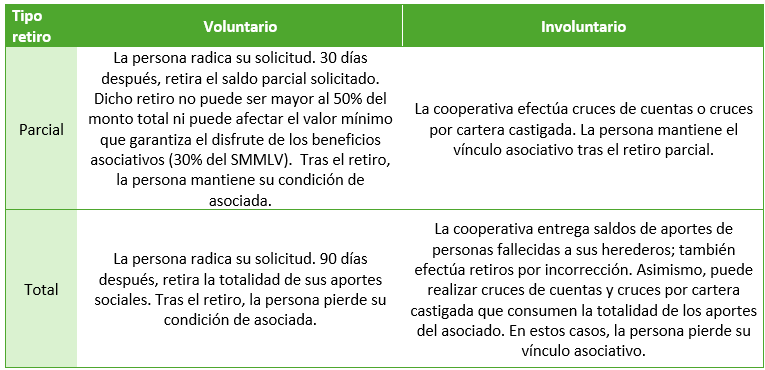

El *retiro total voluntario* ha recibido especial atención por parte del área comercial y de mercadeo. En la actualidad, tanto los canales presenciales como no presenciales aplican un protocolo de atención a los asociados que quieren abandonar definitivamente la cooperativa. Sin embargo, dicho protocolo es reactivo: es decir, solo se pone en marcha cuando el asociado trata de radicar su solicitud. La literatura consultada muestra que otras cooperativas financieras han evidenciado la misma limitación y que, ante ello, han optado por utilizar las bases de datos de sus miembros para desarrollar ejercicios de Machine Learning que les permitan conocer su conducta, predecir su retiro y, a partir de ello, implementar estrategias reactivas de retención (Tafur y Dairo (2024), Bonilla, Montero y González (2021), Zambrano (2019)). Por esta razón, el ejercicio que se presenta a continuación pretende replicar estas experiencias al interior de Confiar, para lo cual explorará el comportamiento de los clientes que se han asociado entre 2017 y 2025 con el fin de predecir la probabilidad de radicación de solicitudes de retiro total, a partir de la aplicación de seis modelos: Regresión Logística, Árbol de Decisiones, Random Forest, KNN Neighbors y Gradient Boosting.

## 2. Objetivo

Predecir la probabilidad de que un asociado de Confiar decida radicar una solicitud de retiro total e identificar los factores que propician su retención.

## 3. Instrumentos

**Librerías:** Openpyxl, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn, Optuna, Shap.

**Modelos:** Baseline, Regresión Logística, Árbol de Decisiones, Random Forest, KNN Neighbors y Gradient Boosting.

## 4. Estructura del proyecto

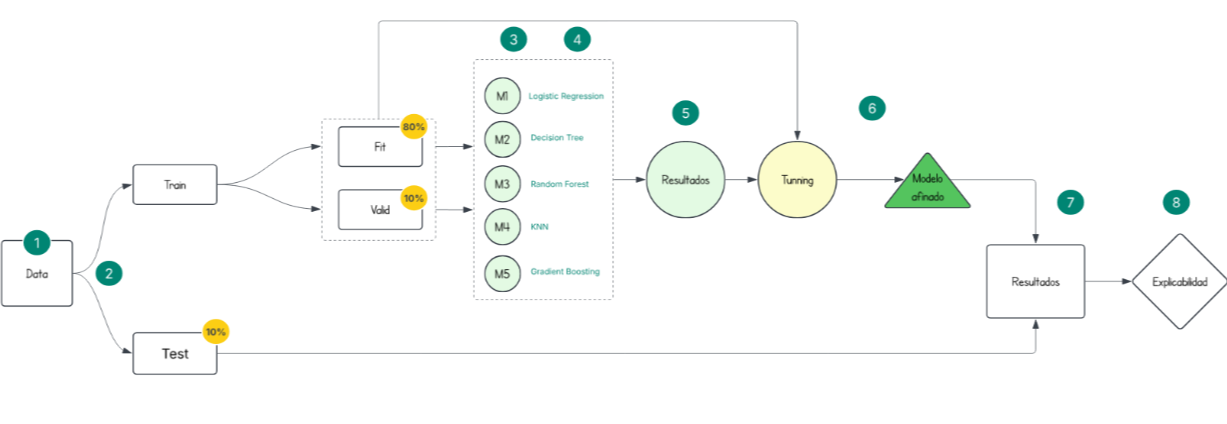


El proceso de entrenamiento, validación y testeo de modelos de machine learning que se propone a continuación consta de los siguientes pasos:

0. Configuración (carga de librerías)

1. Carga del dataset, revisión, ajustes e identificación de variable objetivo.

2. Partición del dataset en conjuntos para entrenamiento (80% de los datos), validación de aprendizaje (10% de los datos) y testeo final (10% de los datos).

3. Preparación del torneo, es decir, selección de los modelos a probar y de las métricas de evaluación.

4. Entrenamiento de los modelos y conservación de aprendizajes obtenidos por cada uno.

5. Validación de los aprendizajes obtenidos por cada modelo. Con base en dicha validación, se define un modelo ganador.

6. Al modelo seleccionado se le realiza ajuste de hiperparámetros y se reentrena con base en los datos combinados de testeo y validación.

7. Testeo final: aplicación de los aprendizajes del modelo reentrenado a la base de datos de testeo.

8. Explicabilidad: identificación de los predictores con mayor influencia sobre la variable objetivo.

## 5. Configuración

In [27]:
# Paso 0: cargar librerías

import openpyxl as ope
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import QuadMesh
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier

import optuna
import shap

RANDOM_STATE = 42

## 6. Dataset

### 6.1 Carga

In [28]:
#Paso 1: cargar la base de datos.

retiro = pd.read_excel("bd_confiar_2.xlsx")

print(f"{retiro.shape[0]:,} rows x {retiro.shape[1]} columns")

c:\Users\carlo\Documents\2026-2030\2026\Unaula\semestre2\IA\proyecto_final_IA\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


194,073 rows x 25 columns


Previamente, se obtuvieron datos tipo panel de corte mensual con variables sociodemográficas, financieras, relacionales y transaccionales de asociados vinculados entre 2017 y 2025. Luego, estos datos fueron transformados teniendo en cuenta:

+ El trabajo de Fajardo y Motta (2019), quienes utilizan el registro más reciente de cada cliente en una base de datos transaccional para construir un dataset de usuarios, en el desarrollo de un modelo de predicción de churn. Al igual que en dicho trabajo, el presente proyecto define un registro único por cliente: para quien radica solicitud de retiro, su registro es aquel correspondiente al mes en el que efectuó la radicación; para quien no radica solicitud de retiro, se toma en cuenta el registro del último periodo transcurrido sin efectuar radicaciones.

+ El trabajo de Raza, Manoj, Singh y Blumenstock (2015), quienes desarrollan un feature engineering en el que crean variables calculadas que resumen el comportamiento de los clientes durante un periodo específico de tiempo, tales como promedios mensuales, porcentajes de actividad y ratios entre valores mínimos y máximos. 

Como resultado, se obtuvo el dataset `bd_confiar_2.xlsx`, que consta de 194.073 registros y 25 columnas. Cada registro representa a un asociado que ingresó a la cooperativa entre 2017 y 2025. Previamente, fue sometido a tratamiento de valores nulos, imputación de valores atípicos y reducción de escala, especialmente en las variables financieras.

|N°|Columna|Significado|
|---|---|---|
|1|Nit|Identificación del cliente|
|2|anio_mes_proceso|Año y mes del registro más reciente del asociado o al momento de efectuar solicitud, según el caso|
|3|cohorte|Año y mes de vinculación del asociado|
|4|saldo_aportes|saldo en aportes más reciente del cliente o al momento de efectuar solicitud, según el caso.|
|5|prom_saldo_capitalizacion_aportes|capitalización de aportes mensual promedio durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|6|porc_meses_capitaliza_aportes|porcentaje de meses en los que el asociado ha efectuado capitalización de aportes durante el tiempo que ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|7|antig_meses|meses transcurridos entre la vinculación y  la solicitud de retiro o el último mes registrado, según el caso.|
|8|sol_retiro|1= radicación de solicitud; 0= no radicación de solicitud|
|9|saldo_ahorro_prog|saldo de CDT y ahorro programado más reciente del asociado o al momento de efectuar solicitud, según el caso|
|10|prom_saldo_ahorro_prog|promedio de saldo de CDT y ahorro programado durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|11|rel_min-max_ahorro_prog|saldo mínimo de CDT y ahorro programado divido entre el saldo máximo de CDT y ahorro programado durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|12|saldo_cta|saldo de cuenta de ahorro más reciente del asociado o al momento de efectuar solicitud, según el caso|
|13|prom_saldo_cta|promedio de sadlo de cuenta de ahorro durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|14|rel_min-max_saldo_cta|saldo mínimo de cuenta de ahorro divido entre el saldo máximo de cuenta de ahorro durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|15|saldo_cartera|saldo de cartera más reciente del asociado o al momento de efectuar solicitud, según el caso|
|16|rel_min-max_saldo_cartera|saldo mínimo de cartera divido entre el saldo máximo de cartera durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|17|prom_asesorias_publiturno|promedio mensual de asesorías en sucursal durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|18|porc_meses_publiturno|porcentaje de meses en los que el asociado ha visitado una sucursal durante el tiempo que ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|19|prom_trx|promedio mensual de transacciones durante el tiempo que el asociado ha permanecido en la cooperativa hasta solicitar retiro o sin solicitar retiro, según el caso.|
|20|edad|años de edad|
|21|femenino|1= femenino;0=masculino|
|22|ingresos|ingresos en pesos|
|23|ed_superior|1=educación superior;0=otro nivel|
|24|zona_med|1=zona Medellín;0=otras zonas|
|25|asalariado|1=asalariado;0=otra ocupación|

### 6.2 Ajustes

In [29]:
# paso 2. Extraer campos que no se incorporan al modelado y retirar duplicados.
 
retiro = pd.read_excel("bd_confiar_2.xlsx").drop(["Nit", "anio_mes_proceso", "cohorte"], axis=1)

retiro = retiro.drop_duplicates()

c:\Users\carlo\Documents\2026-2030\2026\Unaula\semestre2\IA\proyecto_final_IA\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Antes de iniciar con el modelado, es preciso retirar tres variables que no se incorporan en dicho proceso (Nit, anio_mes_proceso, cohorte). Este ajuste hace que aparezcan registros duplicados que se procede a retirar.

In [30]:
# Paso 3: Ofrecer un diagnóstico general de la data tras los ajustes: nulos, duplicados, etc.


print("Dataset Information:")
retiro.info()

print("\nMissing Values:")
print(retiro.isnull().sum())

print("\nDuplicate Rows:")
print(retiro.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
Index: 193910 entries, 0 to 194072
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   saldo_aportes                      193910 non-null  float64
 1   prom_saldo_capitalizacion_aportes  193910 non-null  float64
 2   porc_meses_capitaliza_aportes      193910 non-null  float64
 3   antig_meses                        193910 non-null  int64  
 4   sol_retiro                         193910 non-null  int64  
 5   saldo_ahorro_prog                  193910 non-null  float64
 6   prom_saldo_ahorro_prog             193910 non-null  float64
 7   rel_min-max_ahorro_prog            193910 non-null  float64
 8   saldo_cta                          193910 non-null  float64
 9   prom_saldo_cta                     193910 non-null  float64
 10  rel_min-max_saldo_cta              193910 non-null  float64
 11  prom_saldo_cartera                

El diagnóstico que se presenta en esta celda muestra que todos los campos del dataset son numéricos; además, se evidencia que la aparición de registros nulos causada por el retiro de columnas ha sido solucionada. Con los ajustes efectuados, el dataset que será utilizado en el proceso de modelado queda compuesto por 193.910 registros y 23 columnas.

### 6.3 Variable objetivo

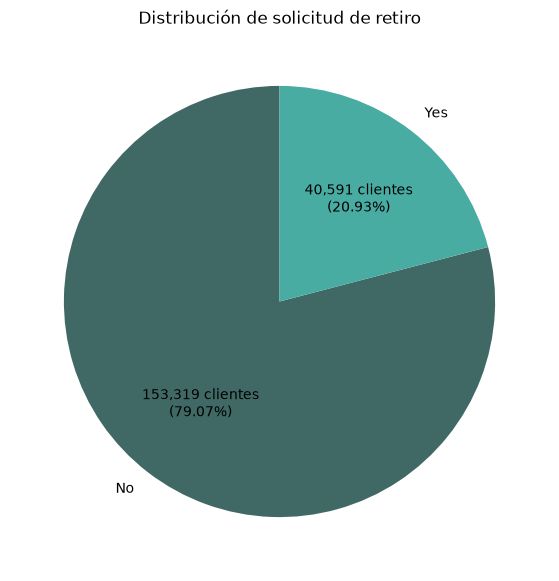

In [31]:
# Paso 4: Presentar la distribución de la variable objetivo

churn_counts = (
retiro.groupby("sol_retiro")["edad"]
.count()
.rename(index={0: "No", 1: "Yes"})
)

total = churn_counts.sum()

plt.figure(figsize=(7, 7))
plt.pie(
churn_counts,
labels=churn_counts.index,
autopct=lambda pct: f"{int(round(pct * total / 100)):,} clientes\n({pct:.2f}%)",
startangle=90,
colors=["#406965", "#49ACA3"]
)

plt.title("Distribución de solicitud de retiro")
plt.show()

El dataset ajustado tiene 193.910 registros. El 20,93% de estos posee radicación de *solicitud de retiro total*.



## 7. Partición del dataset

In [32]:
# Paso 5: Distribuir los datos aleatoriamente de modo estratificado así: 80% para fit, 10% para valid y 10% para test.

# definir variable objetivo y variables predictoras

X = retiro.drop(columns="sol_retiro")
y = retiro["sol_retiro"]

# Distribuir registros entre fit (80%) y conjunto temporal (20%)

X_fit, X_temp, y_fit, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# distribuir el conjunto temporal (20%) en registros para valid (10%) y registros para test (10%)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

In [33]:
# Paso 6: presentar resultados de la partición.

print("partición")
print(f"fit  : {len(X_fit):,} registros ({len(X_fit) / len(X) * 100:.2f}%)")
print(f"valid : {len(X_valid):,} registros ({len(X_valid) / len(X) * 100:.2f}%)")
print(f"test  : {len(X_test):,} registros ({len(X_test) / len(X) * 100:.2f}%)")


partición
fit  : 155,128 registros (80.00%)
valid : 19,391 registros (10.00%)
test  : 19,391 registros (10.00%)


Para desarrollar el proyecto en los términos planteados, se procede a dividir el dataset de forma aleatoria y estratificada, con el fin de garantizar la homogeneidad de cada uno de los tres conjuntos:

+ Conjunto de entrenamiento: agrupa el 80% de los datos.
+ Conjunto de validación del aprendizaje: agrupa el 10% de los datos.
+ Conjunto de prueba: agrupa el 10% de los datos.

## 8. Preparativos para el torneo

### 8.1 Modelos

In [34]:
# Paso 7. Definir los modelos que se van a evaluar

modelos = {
    "Baseline (always 'stayed')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier()
}

# Umbral para la regresión logística
LOGISTIC_THRESHOLD = 0.5


In [35]:
# Paso 8: confirmar carga de modelos

print(type(modelos))
print(modelos.keys())

<class 'dict'>
dict_keys(["Baseline (always 'stayed')", 'Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'Gradient Boosting'])


Se han selecionado tres modelos simples (Regresión Logística, KNN Neighbors y Decision Tree) y dos modelo de ensamble (Gradient Boosting y Random Forest). En cuanto a poder de procesamiento, dos de ellos tienen requerimientos bajos (Regresión Logística, Árbol de Decisiones), dos tienen requerimientos intermedios (Random Forest, KNN Neighbors) y uno tiene requerimientos altos (Gradient Boosting).

__Adicionalmente, se ha incorporado un baseline para identificar el contraste entre modelar y no modelar. Dicho baseline siempre elige la clase más frecuente (en este caso, sol_retiro=0). Asimismo, se ha garantizado que todos los modelos tengan el mismo tratamiento de desbalance: según Chat GPT, "al no especificar hiperparámetros, cada estimador utiliza los valores predeterminados de la versión de scikit-learn instalada".__ 

### 8.2 Métricas

El propósito del modelado es la predicción de la radicación de solicitudes de retiro. Como pudo apreciarse en la descripción, el porcentaje de asociados que efectúa dicho procedimiento dentro del dataset llega el 20,93%. En general, este tipo de desbalance propicia que los modelos tiendan a predecir mejor la clase mayoritaria, que sería, en este caso, el procentaje de asociados que no radican solicitudes de retiro (79,08%).

Con los resultados de este proyecto, se espera *maximizar el número de verdaderos negativos* dentro de la cooperativa, es decir, el número de personas que el modelo predice que efectuarán radicación y que, en la realidad, lo hacen. Dicha maximización puede hacerse a expensas de perder precisión y terminar incluyendo, al interior de dicho conjunto, asociados que en realidad no iban a radicar solicitud de retiro. Finalmente, dicha falta de precisión no es costosa (campañas, souvenirs, comunicaciones dirigidas) y puede alimentar la fidelización de los miembros de la cooperativa.

Por eso, en lo que sigue, se tomarán en consideración las siguientes métricas:

+ **roc-auc:** resume el rendimiento de un modelo en términos de su capacidad de distinguir clases positivas, lo cual lo hace útil para efectuar comparaciones generales.
+ **precision, recall y f1 score obtenido por cada modelo en la clase minoritaria (sol_retiro = 1):** métricas clave para definir umbrales y comparar desempeño en casos como el presentado, donde es importante atender al desbalance de clases, el cual puede ser eclipsado por el roc-auc.

## 9. Entrenamiento

In [36]:
# ============================================================
# PASO 9: K-FOLD CROSS-VALIDATION Y ENTRENAMIENTO FINAL
# ============================================================
#
# PARTICIÓN DE DATOS:
# FIT   = 80% de los datos
# VALID = 10% de los datos
# TEST  = 10% de los datos
#
# PARTE A:
# K-Fold Cross-Validation (k=5) exclusivamente sobre FIT.
#
# PARTE B:
# Entrenamiento final de cada modelo utilizando TODO FIT.
#
# Las tablas de resultados quedan almacenadas en memoria,
# sin imprimirse automáticamente.
# ============================================================


# ============================================================
# CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42
N_SPLITS = 5

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# LISTAS PARA ALMACENAR LOS RESULTADOS
# ============================================================

resultados_tabla_1 = []
resultados_tabla_2 = []


# ============================================================
# DICCIONARIO PARA LOS MODELOS FINALES ENTRENADOS
# ============================================================

modelos_entrenados = {}


# ============================================================
# PROCESAMIENTO DE CADA MODELO
# ============================================================

for nombre_modelo, modelo in modelos.items():

    # ========================================================
    # PARTE A: K-FOLD CROSS-VALIDATION SOBRE FIT
    # ========================================================

    # --------------------------------------------------------
    # ARRAYS PARA ALMACENAR PREDICCIONES OOF
    # --------------------------------------------------------

    y_true_oof = np.zeros(
        len(y_fit),
        dtype=int
    )

    y_pred_oof = np.zeros(
        len(y_fit),
        dtype=int
    )

    y_prob_oof = np.zeros(
        len(y_fit),
        dtype=float
    )

    # --------------------------------------------------------
    # LISTAS PARA LAS MÉTRICAS INDIVIDUALES DE CADA FOLD
    # --------------------------------------------------------

    auc_roc_folds = []

    precision_folds = {
        0: [],
        1: []
    }

    recall_folds = {
        0: [],
        1: []
    }

    f1_folds = {
        0: [],
        1: []
    }

    # --------------------------------------------------------
    # ITERACIÓN SOBRE LOS CINCO FOLDS
    # --------------------------------------------------------

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_fit, y_fit),
        start=1
    ):

        # ----------------------------------------------------
        # DATOS DEL FOLD
        # ----------------------------------------------------

        X_train_fold = X_fit.iloc[train_idx]
        X_val_fold = X_fit.iloc[val_idx]

        y_train_fold = y_fit.iloc[train_idx]
        y_val_fold = y_fit.iloc[val_idx]

        # ----------------------------------------------------
        # CLONAR MODELO
        # ----------------------------------------------------

        modelo_fold = clone(modelo)

        # ----------------------------------------------------
        # ESCALAMIENTO
        #
        # Se aplica a regresión logística y KNN.
        # El scaler se ajusta únicamente con X_train_fold.
        #
        # El baseline y los modelos basados en árboles
        # no necesitan escalamiento.
        # ----------------------------------------------------

        if nombre_modelo in [
            "Logistic Regression",
            "KNN"
        ]:

            modelo_fold = Pipeline([
                ("scaler", StandardScaler()),
                ("model", modelo_fold)
            ])

        # ----------------------------------------------------
        # ENTRENAMIENTO DEL FOLD
        # ----------------------------------------------------

        modelo_fold.fit(
            X_train_fold,
            y_train_fold
        )

        # ----------------------------------------------------
        # PROBABILIDADES DE LA CLASE POSITIVA (1)
        # ----------------------------------------------------

        y_prob = modelo_fold.predict_proba(
            X_val_fold
        )[:, 1]

        # ----------------------------------------------------
        # PREDICCIONES
        # ----------------------------------------------------

        if nombre_modelo == "Logistic Regression":

            y_pred = (
                y_prob >= LOGISTIC_THRESHOLD
            ).astype(int)

        else:

            y_pred = modelo_fold.predict(
                X_val_fold
            )

        # ----------------------------------------------------
        # ALMACENAR PREDICCIONES OOF
        # ----------------------------------------------------

        y_true_oof[val_idx] = y_val_fold
        y_pred_oof[val_idx] = y_pred
        y_prob_oof[val_idx] = y_prob

        # ----------------------------------------------------
        # AUC-ROC DEL FOLD
        # ----------------------------------------------------

        auc_fold = roc_auc_score(
            y_val_fold,
            y_prob
        )

        auc_roc_folds.append(auc_fold)

        # ----------------------------------------------------
        # MÉTRICAS POR CLASE DEL FOLD
        # ----------------------------------------------------

        for clase in [0, 1]:

            precision_fold = precision_score(
                y_val_fold,
                y_pred,
                pos_label=clase,
                zero_division=0
            )

            recall_fold = recall_score(
                y_val_fold,
                y_pred,
                pos_label=clase,
                zero_division=0
            )

            f1_fold = f1_score(
                y_val_fold,
                y_pred,
                pos_label=clase,
                zero_division=0
            )

            precision_folds[clase].append(
                precision_fold
            )

            recall_folds[clase].append(
                recall_fold
            )

            f1_folds[clase].append(
                f1_fold
            )

    # ========================================================
    # RESULTADOS GLOBALES OOF
    #
    # Estas métricas se calculan agrupando las predicciones
    # OOF de los cinco folds.
    # ========================================================

    auc_roc = roc_auc_score(
        y_true_oof,
        y_prob_oof
    )

    accuracy = accuracy_score(
        y_true_oof,
        y_pred_oof
    )

    # ========================================================
    # TABLA 1: MÉTRICAS GLOBALES
    # ========================================================

    resultados_tabla_1.append({
        "modelo": nombre_modelo,
        "auc_roc": auc_roc,
        "accuracy": accuracy,
        "cv_desvest_auc_roc_fit": np.std(
            auc_roc_folds,
            ddof=0
        )
    })

    # ========================================================
    # TABLA 2: MÉTRICAS POR CLASE
    # ========================================================

    for clase in [0, 1]:

        # ----------------------------------------------------
        # MÉTRICAS GLOBALES OOF POR CLASE
        # ----------------------------------------------------

        precision = precision_score(
            y_true_oof,
            y_pred_oof,
            pos_label=clase,
            zero_division=0
        )

        recall = recall_score(
            y_true_oof,
            y_pred_oof,
            pos_label=clase,
            zero_division=0
        )

        f1 = f1_score(
            y_true_oof,
            y_pred_oof,
            pos_label=clase,
            zero_division=0
        )

        # ----------------------------------------------------
        # DESVIACIONES ESTÁNDAR ENTRE LOS CINCO FOLDS
        #
        # ddof=0: desviación estándar poblacional.
        # ----------------------------------------------------

        cv_desvest_precision = np.std(
            precision_folds[clase],
            ddof=0
        )

        cv_desvest_recall = np.std(
            recall_folds[clase],
            ddof=0
        )

        cv_desvest_f1score = np.std(
            f1_folds[clase],
            ddof=0
        )

        # ----------------------------------------------------
        # GUARDAR RESULTADOS
        # ----------------------------------------------------

        resultados_tabla_2.append({
            "modelo": nombre_modelo,
            "sol_retiro": clase,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "CV_desvest_precision_fit": cv_desvest_precision,
            "CV_desvest_recall_fit": cv_desvest_recall,
            "CV_desvest_f1score_fit": cv_desvest_f1score
        })

    # ========================================================
    # PARTE B: ENTRENAMIENTO FINAL SOBRE TODO FIT
    # ========================================================
    #
    # Se crea una nueva copia del modelo.
    # Se entrena utilizando el 100% de X_fit / y_fit.
    #
    # VALID y TEST no intervienen en este entrenamiento.
    # ========================================================

    # --------------------------------------------------------
    # CLONAR MODELO NUEVAMENTE
    # --------------------------------------------------------

    modelo_final = clone(modelo)

    # --------------------------------------------------------
    # PIPELINE PARA LOS MODELOS QUE REQUIEREN ESCALAMIENTO
    # --------------------------------------------------------

    if nombre_modelo in [
        "Logistic Regression",
        "KNN"
    ]:

        modelo_final = Pipeline([
            ("scaler", StandardScaler()),
            ("model", modelo_final)
        ])

    # --------------------------------------------------------
    # ENTRENAR CON TODO FIT (80%)
    # --------------------------------------------------------

    modelo_final.fit(
        X_fit,
        y_fit
    )

    # --------------------------------------------------------
    # GUARDAR MODELO FINAL ENTRENADO
    # --------------------------------------------------------

    modelos_entrenados[nombre_modelo] = modelo_final


# ============================================================
# CREAR TABLAS DE RESULTADOS
# ============================================================

tabla_1 = pd.DataFrame(
    resultados_tabla_1
)

tabla_2 = pd.DataFrame(
    resultados_tabla_2
)


# ============================================================
# ORDENAR TABLA 1 POR AUC-ROC DESCENDENTE
# ============================================================

tabla_1 = tabla_1.sort_values(
    by="auc_roc",
    ascending=False
).reset_index(drop=True)


# ============================================================
# ORDENAR TABLA 2 POR MODELO Y CLASE
# ============================================================

tabla_2 = tabla_2.sort_values(
    by=["modelo", "sol_retiro"]
).reset_index(drop=True)


# ============================================================
# PASO 9 COMPLETADO
# ============================================================
#
# Los siguientes objetos quedan almacenados en memoria:
#
# tabla_1:
#   modelo
#   auc_roc
#   accuracy
#   cv_desvest_auc_roc_fit
#
# tabla_2:
#   modelo
#   sol_retiro
#   precision
#   recall
#   f1_score
#   CV_desvest_precision_fit
#   CV_desvest_recall_fit
#   CV_desvest_f1score_fit
#
# modelos_entrenados:
#   Los seis modelos entrenados con TODO FIT.
#
# Las tablas NO se imprimen automáticamente.
# Se pueden consultar posteriormente con display(tabla_1)
# y display(tabla_2).
# ============================================================

print("K-Fold y entrenamiento final completados.")

K-Fold y entrenamiento final completados.


En este punto, se le solicitó a Chat GPT generar un código que permitiera evaluar el comportamiento de los seis modelos con el conjunto de datos de entrenamiento mediante la técnica de K-Fold Cross-Validation (k=5) y, seguidamente, entrenar cada modelo y almacenar sus aprendizajes. El código incluyó un pipeline para escalar los datos en el caso de la Regresión Logística y el modelo KNN Neighbors, que requieren de dicho ajuste. Asimismo, se construyeron tablas con los resultados, las cuales se presentan más adelante. __Entre los resultados, aparece la desviación estandar entre folds de las métricas consideradas.__ 

## 10. Validación de aprendizaje

In [37]:
# ============================================================
# PASO 10
# EVALUACIÓN DE LOS MODELOS ENTRENADOS SOBRE VALID
# ============================================================
#
# FIT   = 80% -> utilizado para entrenar los modelos
# VALID = 10% -> utilizado exclusivamente para evaluación
# TEST  = 10% -> permanece reservado
#
# Los modelos utilizados son los almacenados en:
#     modelos_entrenados
#
# IMPORTANTE:
# - Aquí NO se utiliza .fit().
# - VALID no participa en ningún entrenamiento.
# - Logistic Regression y KNN ya contienen su StandardScaler
#   dentro del Pipeline entrenado en el Paso 9.
# - El baseline no requiere escalamiento.
# - La variabilidad de las métricas se calcula mediante
#   cinco particiones estratificadas de VALID.
# - Estas particiones NO reentrenan los modelos.
# ============================================================


# ============================================================
# CONFIGURACIÓN PARA CALCULAR LA VARIABILIDAD EN VALID
# ============================================================

RANDOM_STATE = 42
N_SPLITS_VALID = 5

cv_valid = StratifiedKFold(
    n_splits=N_SPLITS_VALID,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# LISTAS PARA GUARDAR RESULTADOS
# ============================================================

resultados_valid_tabla_1 = []
resultados_valid_tabla_2 = []


# ============================================================
# PREPARAR LAS ETIQUETAS REALES DE VALID
# ============================================================

y_valid_array = np.asarray(y_valid)


# ============================================================
# APLICAR CADA MODELO SOBRE VALID
# ============================================================

for nombre_modelo, modelo_entrenado in modelos_entrenados.items():

    # ========================================================
    # PREDICCIONES SOBRE TODO VALID
    # ========================================================
    #
    # Los modelos ya están entrenados.
    # Si existe un Pipeline, el escalamiento se aplica
    # automáticamente utilizando el scaler ajustado con FIT.
    # ========================================================

    y_prob_valid = modelo_entrenado.predict_proba(
        X_valid
    )[:, 1]

    # --------------------------------------------------------
    # PREDICCIONES DE CLASE
    # --------------------------------------------------------

    if nombre_modelo == "Logistic Regression":

        y_pred_valid = (
            y_prob_valid >= LOGISTIC_THRESHOLD
        ).astype(int)

    else:

        y_pred_valid = modelo_entrenado.predict(
            X_valid
        )

    # Convertir las predicciones a arrays para trabajar
    # con los índices posicionales de los folds.

    y_pred_valid = np.asarray(y_pred_valid)
    y_prob_valid = np.asarray(y_prob_valid)

    # ========================================================
    # TABLA VALID 1
    # MÉTRICAS GLOBALES SOBRE TODO VALID
    # ========================================================

    auc_roc = roc_auc_score(
        y_valid_array,
        y_prob_valid
    )

    accuracy = accuracy_score(
        y_valid_array,
        y_pred_valid
    )

    # ========================================================
    # CALCULAR MÉTRICAS POR FOLD PARA LA DESVIACIÓN ESTÁNDAR
    # ========================================================
    #
    # Se divide VALID en cinco folds estratificados.
    #
    # Los modelos NO se vuelven a entrenar.
    # Solo se calculan las métricas sobre las observaciones
    # correspondientes a cada fold.
    # ========================================================

    auc_roc_folds = []

    precision_folds = {
        0: [],
        1: []
    }

    recall_folds = {
        0: [],
        1: []
    }

    f1_folds = {
        0: [],
        1: []
    }

    # --------------------------------------------------------
    # ITERACIÓN SOBRE LOS CINCO FOLDS DE VALID
    # --------------------------------------------------------

    for fold, (_, fold_idx) in enumerate(
        cv_valid.split(X_valid, y_valid_array),
        start=1
    ):

        # ----------------------------------------------------
        # EXTRAER LAS OBSERVACIONES DEL FOLD
        # ----------------------------------------------------

        y_true_fold = y_valid_array[fold_idx]
        y_pred_fold = y_pred_valid[fold_idx]
        y_prob_fold = y_prob_valid[fold_idx]

        # ----------------------------------------------------
        # AUC-ROC DEL FOLD
        # ----------------------------------------------------

        auc_fold = roc_auc_score(
            y_true_fold,
            y_prob_fold
        )

        auc_roc_folds.append(auc_fold)

        # ----------------------------------------------------
        # MÉTRICAS POR CLASE DEL FOLD
        # ----------------------------------------------------

        for clase in [0, 1]:

            precision_fold = precision_score(
                y_true_fold,
                y_pred_fold,
                pos_label=clase,
                zero_division=0
            )

            recall_fold = recall_score(
                y_true_fold,
                y_pred_fold,
                pos_label=clase,
                zero_division=0
            )

            f1_fold = f1_score(
                y_true_fold,
                y_pred_fold,
                pos_label=clase,
                zero_division=0
            )

            precision_folds[clase].append(
                precision_fold
            )

            recall_folds[clase].append(
                recall_fold
            )

            f1_folds[clase].append(
                f1_fold
            )

    # ========================================================
    # DESVIACIÓN ESTÁNDAR DEL AUC-ROC EN VALID
    # ========================================================

    cv_desvest_auc_roc_valid = np.std(
        auc_roc_folds,
        ddof=0
    )

    # --------------------------------------------------------
    # GUARDAR RESULTADOS DE LA TABLA VALID 1
    # --------------------------------------------------------

    resultados_valid_tabla_1.append({
        "modelo": nombre_modelo,
        "auc_roc": auc_roc,
        "accuracy": accuracy,
        "cv_desvest_auc_roc_valid": cv_desvest_auc_roc_valid
    })

    # ========================================================
    # TABLA VALID 2
    # MÉTRICAS GLOBALES POR CLASE
    # ========================================================

    for clase in [0, 1]:

        # ----------------------------------------------------
        # MÉTRICAS CALCULADAS SOBRE TODO VALID
        # ----------------------------------------------------

        precision = precision_score(
            y_valid_array,
            y_pred_valid,
            pos_label=clase,
            zero_division=0
        )

        recall = recall_score(
            y_valid_array,
            y_pred_valid,
            pos_label=clase,
            zero_division=0
        )

        f1 = f1_score(
            y_valid_array,
            y_pred_valid,
            pos_label=clase,
            zero_division=0
        )

        # ----------------------------------------------------
        # DESVIACIONES ESTÁNDAR ENTRE LOS FOLDS
        # ----------------------------------------------------

        cv_desvest_precision = np.std(
            precision_folds[clase],
            ddof=0
        )

        cv_desvest_recall = np.std(
            recall_folds[clase],
            ddof=0
        )

        cv_desvest_f1score = np.std(
            f1_folds[clase],
            ddof=0
        )

        # ----------------------------------------------------
        # GUARDAR RESULTADOS DE LA TABLA VALID 2
        # ----------------------------------------------------

        resultados_valid_tabla_2.append({
            "modelo": nombre_modelo,
            "sol_retiro": clase,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "CV_desvest_precision_valid": cv_desvest_precision,
            "CV_desvest_recall_valid": cv_desvest_recall,
            "CV_desvest_f1score_valid": cv_desvest_f1score
        })


# ============================================================
# CREAR TABLAS DE RESULTADOS
# ============================================================

tabla_valid_1 = pd.DataFrame(
    resultados_valid_tabla_1
)

tabla_valid_2 = pd.DataFrame(
    resultados_valid_tabla_2
)


# ============================================================
# ORDENAR TABLA VALID 1 POR AUC-ROC DESCENDENTE
# ============================================================

tabla_valid_1 = tabla_valid_1.sort_values(
    by="auc_roc",
    ascending=False
).reset_index(drop=True)


# ============================================================
# ORDENAR TABLA VALID 2 POR MODELO Y CLASE
# ============================================================

tabla_valid_2 = tabla_valid_2.sort_values(
    by=[
        "modelo",
        "sol_retiro"
    ]
).reset_index(drop=True)


# ============================================================
# PASO 10 COMPLETADO
# ============================================================
#
# Las siguientes variables quedan almacenadas en memoria:
#
# tabla_valid_1:
#   - modelo
#   - auc_roc
#   - accuracy
#   - cv_desvest_auc_roc_valid
#
# tabla_valid_2:
#   - modelo
#   - sol_retiro
#   - precision
#   - recall
#   - f1_score
#   - CV_desvest_precision_valid
#   - CV_desvest_recall_valid
#   - CV_desvest_f1score_valid
#
# Los modelos permanecen almacenados en:
#   modelos_entrenados
#
# Las tablas NO se imprimen automáticamente.
# ============================================================

print("Evaluación sobre VALID completada.")

Evaluación sobre VALID completada.


Luego, se le pidió a Chat GPT generar un código que permitiera evaluar los apendizajes obtenidos por los seis modelos tras el entrenamiento. El código incluyó un pipeline para escalar los datos en el caso de la Regresión Logística y el modelo KNN Neighbors, que requieren de dicho ajuste. Asimismo, se construyeron tablas con los resultados, las cuales se presentan a continuación.En este punto, se le solicitó a Chat GPT generar un código que permitiera evaluar el comportamiento de los seis modelos con el conjunto de datos de entrenamiento mediante la técnica de K-Fold Cross-Validation (k=5) y, seguidamente, entrenar cada modelo y almacenar sus aprendizajes. El código incluyó un pipeline para escalar los datos en el caso de la Regresión Logística y el modelo KNN Neighbors, que requieren de dicho ajuste. Asimismo, se construyeron tablas con los resultados, las cuales se presentan más adelante. __Entre los resultados, aparece la desviación estandar entre folds de las métricas consideradas.__ 


## 10. Resultados de la validación y selección del modelo para afinar

In [38]:
# ============================================================
# PASO 11
# COMPARACIÓN DE RESULTADOS: FIT VS VALID
# ============================================================
#
# tabla_1:
#     Métricas globales OOF del K-Fold sobre FIT.
#
# tabla_2:
#     Métricas por clase del K-Fold sobre FIT.
#
# tabla_valid_1:
#     Métricas de los modelos entrenados con TODO FIT
#     y evaluados posteriormente sobre VALID.
#
# tabla_valid_2:
#     Métricas por clase de esos modelos sobre VALID.
#
# Se incluyen:
#     - Baseline
#     - AUC-ROC
#     - Accuracy
#     - Precision, recall y F1-score por clase
#     - Desviaciones estándar entre folds
#
# Las tablas comparativas se publican al final.
# ============================================================


# ============================================================
# TABLA 1
# MÉTRICAS GLOBALES: FIT VS VALID
# ============================================================

tabla_1_comparacion = tabla_1.merge(
    tabla_valid_1,
    on="modelo",
    suffixes=("_fit", "_valid")
)


# ------------------------------------------------------------
# SELECCIONAR Y ORDENAR COLUMNAS
# ------------------------------------------------------------

tabla_1_comparacion = tabla_1_comparacion[
    [
        "modelo",

        # AUC-ROC
        "auc_roc_fit",
        "auc_roc_valid",

        # Desviación estándar del AUC-ROC
        "cv_desvest_auc_roc_fit",
        "cv_desvest_auc_roc_valid",

    ]
]


# ------------------------------------------------------------
# REDONDEAR RESULTADOS
# ------------------------------------------------------------

tabla_1_comparacion = tabla_1_comparacion.round(4)


# ============================================================
# TABLA 2
# MÉTRICAS POR CLASE: FIT VS VALID
# ============================================================

tabla_2_comparacion = tabla_2.merge(
    tabla_valid_2,
    on=["modelo", "sol_retiro"],
    suffixes=("_fit", "_valid")
)


# ------------------------------------------------------------
# SELECCIONAR Y ORDENAR COLUMNAS
# ------------------------------------------------------------

tabla_2_comparacion = tabla_2_comparacion[
    [
        "modelo",
        "sol_retiro",

        # Precision
        "precision_fit",
        "precision_valid",

        # Desviación estándar de precision
        "CV_desvest_precision_fit",
        "CV_desvest_precision_valid",

        # Recall
        "recall_fit",
        "recall_valid",

        # Desviación estándar de recall
        "CV_desvest_recall_fit",
        "CV_desvest_recall_valid",

        # F1-score
        "f1_score_fit",
        "f1_score_valid",

        # Desviación estándar de F1-score
        "CV_desvest_f1score_fit",
        "CV_desvest_f1score_valid"
    ]
]


# ------------------------------------------------------------
# REDONDEAR RESULTADOS
# ------------------------------------------------------------

tabla_2_comparacion = tabla_2_comparacion.round(4)


# ============================================================
# VISUALIZAR RESULTADOS
# ============================================================

print("=" * 90)
print("TABLA 1 - COMPARACIÓN FIT VS VALID")
print("=" * 90)

display(tabla_1_comparacion)

print("\n")

print("=" * 110)
print("TABLA 2 - COMPARACIÓN FIT VS VALID POR CLASE")
print("=" * 110)

display(tabla_2_comparacion)

TABLA 1 - COMPARACIÓN FIT VS VALID


,modelo,auc_roc_fit,auc_roc_valid,cv_desvest_auc_roc_fit,cv_desvest_auc_roc_valid
0,Random Forest,0.8955,0.8960,0.0016,0.0040
1,Gradient Boosting,0.8872,0.8866,0.0018,0.0042
2,Logistic Regression,0.7872,0.7947,0.0022,0.0036
3,KNN,0.7797,0.7841,0.0025,0.0054
4,Decision Tree,0.6952,0.7051,0.0035,0.0080
5,Baseline (always 'stayed'),0.5000,0.5000,0.0000,0.0000




TABLA 2 - COMPARACIÓN FIT VS VALID POR CLASE


,modelo,sol_retiro,precision_fit,precision_valid,CV_desvest_precision_fit,CV_desvest_precision_valid,recall_fit,recall_valid,CV_desvest_recall_fit,CV_desvest_recall_valid,f1_score_fit,f1_score_valid,CV_desvest_f1score_fit,CV_desvest_f1score_valid
0,Baseline (always 'stayed'),0,0.7907,0.7907,0.0000,0.0001,1.0000,1.0000,0.0000,0.0000,0.8831,0.8831,0.0000,0.0001
1,Baseline (always 'stayed'),1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,Decision Tree,0,0.8729,0.8772,0.0017,0.0034,0.8673,0.8701,0.0033,0.0076,0.8701,0.8736,0.0017,0.0046
3,Decision Tree,1,0.5106,0.5239,0.0059,0.0156,0.5231,0.5400,0.0076,0.0140,0.5168,0.5318,0.0053,0.0125
4,Gradient Boosting,0,0.8705,0.8720,0.0015,0.0012,0.9543,0.9536,0.0007,0.0034,0.9105,0.9110,0.0009,0.0017
5,Gradient Boosting,1,0.7289,0.7290,0.0044,0.0146,0.4639,0.4713,0.0073,0.0058,0.5669,0.5725,0.0066,0.0062
6,KNN,0,0.8569,0.8605,0.0010,0.0024,0.8985,0.8985,0.0014,0.0031,0.8772,0.8791,0.0010,0.0021
7,KNN,1,0.5306,0.5399,0.0046,0.0097,0.4333,0.4499,0.0046,0.0109,0.4771,0.4908,0.0043,0.0094
8,Logistic Regression,0,0.8152,0.8180,0.0007,0.0009,0.9620,0.9618,0.0010,0.0022,0.8825,0.8841,0.0005,0.0010
9,Logistic Regression,1,0.5508,0.5707,0.0071,0.0120,0.1761,0.1919,0.0044,0.0054,0.2669,0.2872,0.0056,0.0062


Los resultados obtenidos permiten apreciar que:

- __El baseline se comportó de la manera esperada. Al contrastarlo con el comportamiento de los demás modelos, se puede afirmar, en primer lugar, que estos últimos (roc-auc) alcanzan rendimientos superiores a los del azar. En segundo lugar, se puede decir que el rendimiento de los demás modelos en cuanto a precisión, recall y f1 score en la clase minoritaria se encuentran por encima del rendimiento de un predictor aleatorio. En resumen, existe una diferencia entre modelar y no modelar los datos.__ 

- En cuanto a rendimiento general (roc-auc), Random Forest y Gradiente Boosting se muestran superiores a los demás, tanto en la fase de entrenamiento como en la de validación. Les siguen, en orden, Regresión Logística, KNN Neighbors y Ramdom Forest. Todos dejan ver una mejora en el tránsito entre una fase y otra. a excepción del Gradient Boosting. En cuanto a la desviación estándar de los folds, Gradient Boosting presenta la variación más baja durante el entrenamiento. Sin embargo, durante la validación, la Regresión Logística alcanzó las métricas de variación más bajas. La diferencia más baja entre las desviaciones estándar de folds obtenidas en entrenamiento y validación se presentó en el caso de la Regresión Logística.

- En cuanto a recall de la clase minoritaria (sol_retiro=1), Decision Tree y Random Forest muestran los mejores resultados, seguidos en orden por Gradient Boosting, KNN y Regresión Logística. En cuanto a la desviación estándar de los folds, la regresión logística aparece como el que mantiene los valores más bajos en la fase de validación.

En términos de los datos, Random Forest y Gradient Boosting aparecen como las opciones que conjugan mejores rendimientos en métricas generales y en métricas específicas de la clase minoritaria. *Sin embargo, la tendencia al sobreajuste del primero, y el poder de procesamiento exigido por el segundo, nos animan a explorar la alternativa de afinar el modelo de Regresión Logística para incrementar su rendimiento, ya que es más simple que los anteriores, más estable en términos de desviación estándar entre folds, más explicable y demanda menor poder de procesamiento.*

## 11. Afinación

## 11.1. Hiperparámetros

In [39]:
# ============================================================
# PASO 12
# AJUSTE DE REGRESIÓN LOGÍSTICA MEDIANTE OPTUNA
# ============================================================
#
# OBJETIVO:
# Encontrar el class_weight de la clase 1 que permita alcanzar
# un recall medio de al menos 0.75.
#
# HIPERPARÁMETRO:
# class_weight de la clase 1.
# El peso de la clase 0 permanece fijo en 1.0.
#
# NO EXISTEN RESTRICCIONES SOBRE F1-SCORE.
#
# THRESHOLD:
# Fijo en 0.50.
#
# CV:
# Stratified K-Fold, k=5.
#
# DATOS:
# FIT + VALID.
#
# TEST:
# Permanece completamente reservado.
# ============================================================


# ============================================================
# 1. UNIR FIT + VALID
# ============================================================

X_fit_valid = pd.concat(
    [X_fit, X_valid],
    axis=0
).reset_index(drop=True)

y_fit_valid = pd.concat(
    [y_fit, y_valid],
    axis=0
).reset_index(drop=True)

print("=" * 70)
print("DATOS UTILIZADOS PARA EL AJUSTE")
print("=" * 70)

print(f"Observaciones FIT + VALID: {len(X_fit_valid)}")
print(f"Variables: {X_fit_valid.shape[1]}")


# ============================================================
# 2. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42
N_SPLITS = 5

LOGISTIC_THRESHOLD = 0.50
RECALL_OBJETIVO = 0.75

N_TRIALS = 100

cv_ajuste = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# 3. FUNCIÓN OBJETIVO DE OPTUNA
# ============================================================
#
# Se busca un recall medio >= 0.75.
#
# Si varios valores alcanzan el objetivo, se prefiere el que
# produzca un recall medio más cercano a 0.75 desde arriba.
#
# Si ningún valor alcanza el objetivo, se selecciona el que
# más se aproxime por debajo y se informa que no se alcanzó.
#
# F1-score y precision se registran como métricas informativas,
# pero NO restringen la optimización.
# ============================================================

def objective_logistic(trial):

    class_weight_1 = trial.suggest_float(
        "class_weight_1",
        0.1,
        20.0,
        log=True
    )

    class_weight = {
        0: 1.0,
        1: class_weight_1
    }

    f1_scores = []
    recall_scores = []
    precision_scores = []

    for train_idx, val_idx in cv_ajuste.split(
        X_fit_valid,
        y_fit_valid
    ):

        # ----------------------------------------------------
        # DATOS DEL FOLD
        # ----------------------------------------------------

        X_train_fold = X_fit_valid.iloc[train_idx]
        X_val_fold = X_fit_valid.iloc[val_idx]

        y_train_fold = y_fit_valid.iloc[train_idx]
        y_val_fold = y_fit_valid.iloc[val_idx]

        # ----------------------------------------------------
        # PIPELINE
        # El scaler se ajusta exclusivamente con el fold
        # de entrenamiento.
        # ----------------------------------------------------

        modelo_fold = Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    class_weight=class_weight,
                    max_iter=5000,
                    random_state=RANDOM_STATE
                )
            )
        ])

        # ----------------------------------------------------
        # ENTRENAMIENTO
        # ----------------------------------------------------

        modelo_fold.fit(
            X_train_fold,
            y_train_fold
        )

        # ----------------------------------------------------
        # PROBABILIDADES Y PREDICCIONES
        # Threshold fijo en 0.50.
        # ----------------------------------------------------

        y_prob_fold = modelo_fold.predict_proba(
            X_val_fold
        )[:, 1]

        y_pred_fold = (
            y_prob_fold >= LOGISTIC_THRESHOLD
        ).astype(int)

        # ----------------------------------------------------
        # MÉTRICAS DE LA CLASE 1
        # ----------------------------------------------------

        f1 = f1_score(
            y_val_fold,
            y_pred_fold,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_val_fold,
            y_pred_fold,
            pos_label=1,
            zero_division=0
        )

        precision = precision_score(
            y_val_fold,
            y_pred_fold,
            pos_label=1,
            zero_division=0
        )

        f1_scores.append(f1)
        recall_scores.append(recall)
        precision_scores.append(precision)

    # --------------------------------------------------------
    # PROMEDIOS DE LOS CINCO FOLDS
    # --------------------------------------------------------

    f1_medio = np.mean(f1_scores)
    recall_medio = np.mean(recall_scores)
    precision_media = np.mean(precision_scores)

    desvest_recall = np.std(
        recall_scores,
        ddof=0
    )

    # --------------------------------------------------------
    # GUARDAR MÉTRICAS DEL TRIAL
    # --------------------------------------------------------

    trial.set_user_attr(
        "f1_medio",
        float(f1_medio)
    )

    trial.set_user_attr(
        "recall_medio",
        float(recall_medio)
    )

    trial.set_user_attr(
        "precision_media",
        float(precision_media)
    )

    trial.set_user_attr(
        "desvest_recall",
        float(desvest_recall)
    )

    # --------------------------------------------------------
    # FUNCIÓN OBJETIVO
    #
    # Se minimiza la distancia al objetivo de recall.
    #
    # Si recall >= 0.75:
    #   Penalización = exceso sobre 0.75.
    #
    # Si recall < 0.75:
    #   Penalización = 1 + distancia por debajo de 0.75.
    #
    # Así, cualquier solución que cumpla el objetivo tendrá
    # prioridad frente a una que no lo cumpla.
    #
    # NO se aplica ninguna restricción de F1-score.
    # --------------------------------------------------------

    if recall_medio >= RECALL_OBJETIVO:

        objetivo = recall_medio - RECALL_OBJETIVO

    else:

        objetivo = (
            1.0 + RECALL_OBJETIVO - recall_medio
        )

    return objetivo


# ============================================================
# 4. CREAR ESTUDIO OPTUNA
# ============================================================

study_logistic = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)


# ============================================================
# 5. EJECUTAR OPTIMIZACIÓN
# ============================================================

study_logistic.optimize(
    objective_logistic,
    n_trials=N_TRIALS
)


# ============================================================
# 6. RECUPERAR EL MEJOR CLASS_WEIGHT
# ============================================================

class_weight_1_optimo = (
    study_logistic.best_params[
        "class_weight_1"
    ]
)

class_weight_optimo = {
    0: 1.0,
    1: class_weight_1_optimo
}


# ============================================================
# 7. EVALUAR EL CLASS_WEIGHT SELECCIONADO MEDIANTE CV
# ============================================================
#
# Se repite la validación cruzada para obtener las métricas
# finales del valor seleccionado.
#
# Se calculan F1, recall, precision y desviación estándar
# del recall entre los cinco folds.
# ============================================================

f1_scores_optimo = []
recall_scores_optimo = []
precision_scores_optimo = []

for train_idx, val_idx in cv_ajuste.split(
    X_fit_valid,
    y_fit_valid
):

    # --------------------------------------------------------
    # DATOS DEL FOLD
    # --------------------------------------------------------

    X_train_fold = X_fit_valid.iloc[train_idx]
    X_val_fold = X_fit_valid.iloc[val_idx]

    y_train_fold = y_fit_valid.iloc[train_idx]
    y_val_fold = y_fit_valid.iloc[val_idx]

    # --------------------------------------------------------
    # PIPELINE CON EL CLASS_WEIGHT SELECCIONADO
    # --------------------------------------------------------

    modelo_fold = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight=class_weight_optimo,
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ])

    # --------------------------------------------------------
    # ENTRENAR FOLD
    # --------------------------------------------------------

    modelo_fold.fit(
        X_train_fold,
        y_train_fold
    )

    # --------------------------------------------------------
    # PREDICCIONES CON THRESHOLD 0.50
    # --------------------------------------------------------

    y_prob_fold = modelo_fold.predict_proba(
        X_val_fold
    )[:, 1]

    y_pred_fold = (
        y_prob_fold >= LOGISTIC_THRESHOLD
    ).astype(int)

    # --------------------------------------------------------
    # MÉTRICAS DE LA CLASE 1
    # --------------------------------------------------------

    f1 = f1_score(
        y_val_fold,
        y_pred_fold,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_val_fold,
        y_pred_fold,
        pos_label=1,
        zero_division=0
    )

    precision = precision_score(
        y_val_fold,
        y_pred_fold,
        pos_label=1,
        zero_division=0
    )

    f1_scores_optimo.append(f1)
    recall_scores_optimo.append(recall)
    precision_scores_optimo.append(precision)


# ============================================================
# 8. MÉTRICAS FINALES DE VALIDACIÓN CRUZADA
# ============================================================

F1_CV_OPTIMO = np.mean(
    f1_scores_optimo
)

RECALL_CV_OPTIMO = np.mean(
    recall_scores_optimo
)

PRECISION_CV_OPTIMO = np.mean(
    precision_scores_optimo
)

DESVEST_RECALL_CV_OPTIMO = np.std(
    recall_scores_optimo,
    ddof=0
)

RECALL_OBJETIVO_CUMPLIDO = (
    RECALL_CV_OPTIMO >= RECALL_OBJETIVO
)


# ============================================================
# 9. ENTRENAR MODELO FINAL CON TODO FIT + VALID
# ============================================================
#
# El modelo definitivo se entrena con el 90% de los datos.
# TEST permanece reservado y no se utiliza.
# ============================================================

modelo_logistic_final = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight=class_weight_optimo,
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])

modelo_logistic_final.fit(
    X_fit_valid,
    y_fit_valid
)


# ============================================================
# 10. RESULTADOS DEL AJUSTE
# ============================================================

print("\n")
print("=" * 70)
print("RESULTADOS DEL AJUSTE DE REGRESIÓN LOGÍSTICA")
print("=" * 70)

print("\nDatos utilizados:")
print("  FIT + VALID")

print("\nClass weight óptimo:")

print(
    "  Clase 0 = 1.00000000"
)

print(
    f"  Clase 1 = {class_weight_1_optimo:.8f}"
)

print("\nConfiguración:")

print(
    f"  Threshold = {LOGISTIC_THRESHOLD:.2f}"
)

print("\nMétricas CV de la clase 1:")

print(
    f"  F1 medio = {F1_CV_OPTIMO:.4f}"
)

print(
    f"  Recall medio = {RECALL_CV_OPTIMO:.4f}"
)

print(
    f"  Desviación estándar del recall entre folds = "
    f"{DESVEST_RECALL_CV_OPTIMO:.4f}"
)

print(
    f"  Precision media = {PRECISION_CV_OPTIMO:.4f}"
)

print(
    f"  Objetivo de recall >= {RECALL_OBJETIVO:.2f}: "
    f"{'CUMPLIDO' if RECALL_OBJETIVO_CUMPLIDO else 'NO CUMPLIDO'}"
)

print("\nModelo final:")
print(
    "  Entrenado con todo FIT + VALID"
)

print(
    "  Pipeline con StandardScaler y LogisticRegression"
)

print(
    "  Test permanece reservado"
)

print("=" * 70)

[I 2026-10-12 22:43:17,612] A new study created in memory with name: no-name-d2b2c352-8188-40ce-b0e4-501c9ed0dbf0


DATOS UTILIZADOS PARA EL AJUSTE
Observaciones FIT + VALID: 174519
Variables: 21


[I 2026-10-12 22:43:18,722] Trial 0 finished with value: 1.6592027860590353 and parameters: {'class_weight_1': 0.7274917088027808}. Best is trial 0 with value: 1.6592027860590353.
[I 2026-10-12 22:43:19,672] Trial 1 finished with value: 0.23445193028401157 and parameters: {'class_weight_1': 15.40359659501924}. Best is trial 1 with value: 0.23445193028401157.
[I 2026-10-12 22:43:20,652] Trial 2 finished with value: 0.07664494044032133 and parameters: {'class_weight_1': 4.83437145318464}. Best is trial 2 with value: 0.07664494044032133.
[I 2026-10-12 22:43:21,637] Trial 3 finished with value: 1.1922973579328793 and parameters: {'class_weight_1': 2.385234757844707}. Best is trial 2 with value: 0.07664494044032133.
[I 2026-10-12 22:43:22,724] Trial 4 finished with value: 1.7472079280333395 and parameters: {'class_weight_1': 0.22856175997064762}. Best is trial 2 with value: 0.07664494044032133.
[I 2026-10-12 22:43:23,780] Trial 5 finished with value: 1.7472079280333395 and parameters: {'cla



RESULTADOS DEL AJUSTE DE REGRESIÓN LOGÍSTICA

Datos utilizados:
  FIT + VALID

Class weight óptimo:
  Clase 0 = 1.00000000
  Clase 1 = 3.88118798

Configuración:
  Threshold = 0.50

Métricas CV de la clase 1:
  F1 medio = 0.5119
  Recall medio = 0.7549
  Desviación estándar del recall entre folds = 0.0058
  Precision media = 0.3872
  Objetivo de recall >= 0.75: CUMPLIDO

Modelo final:
  Entrenado con todo FIT + VALID
  Pipeline con StandardScaler y LogisticRegression
  Test permanece reservado


Uno de los hiperparámetros de la Regresión Logística es el class weight, el cual se utiliza en casos donde existen datos desbalanceados, como el que se viene trabajando. Dicho hiperparámetro les asigna pesos diferenciales a las clases minoritas y mayoritarias, de modo que el modelo se ve obligado a prestarle más atención a la clase minoritaria.

En nuestro caso, definimos una regla dura de negocio y procedimos a utilizar la librería optuna para encontrar, a partir de la data combinada de train y test, el class weight de la clase 1 que permita alcanzar un recall medio de, al menos, 0,75, a través de validación cruzada. El valor obtenido para el hiperparámetro nombrado fue 3,88118798. __Cabe resaltar, además, que la desviación estándar del recall entre folds fue de 0,0058, silimar a los valores obtenidos durante las fases de entrenamiento y validación para la clase minoritaria.__

## 11.2 Reentrenamiento con class weight óptimo

In [40]:
# ============================================================
# PASO 13
# REENTRENAMIENTO CON CLASS_WEIGHT ÓPTIMO
# VALIDACIÓN CRUZADA Y EVALUACIÓN SOBRE TEST
# ============================================================
#
# El class_weight fue previamente obtenido mediante Optuna.
#
# 1. Se realiza Cross-Validation = 5 sobre FIT + VALID.
# 2. Se calcula la desviación estándar del recall entre folds.
# 3. Se reentrena el modelo con todo FIT + VALID.
# 4. Se evalúa el modelo final sobre TEST.
#
# IMPORTANTE:
# - TEST no participa en la validación cruzada.
# - TEST no participa en el entrenamiento.
# - Se mantiene el Pipeline StandardScaler + LogisticRegression.
# - El threshold de clasificación permanece en 0.50.
# ============================================================


# ============================================================
# 1. CLASS_WEIGHT ÓPTIMO OBTENIDO POR OPTUNA
# ============================================================

class_weight_optimo = {
    0: 1.0,
    1: class_weight_1_optimo
}

print("=" * 70)
print("CLASS_WEIGHT ÓPTIMO OBTENIDO POR OPTUNA")
print("=" * 70)

print(
    f"Clase 0 = {class_weight_optimo[0]:.8f}"
)

print(
    f"Clase 1 = {class_weight_optimo[1]:.8f}"
)


# ============================================================
# 2. CONFIGURAR CROSS-VALIDATION
# ============================================================

RANDOM_STATE = 42
N_SPLITS = 5
LOGISTIC_THRESHOLD = 0.50

cv_final = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# 3. VALIDACIÓN CRUZADA SOBRE FIT + VALID
# ============================================================
#
# Se mantiene fijo el class_weight seleccionado por Optuna.
#
# En cada fold:
# - El scaler se ajusta solo con el fold de entrenamiento.
# - LogisticRegression se entrena solo con ese fold.
# - Se evalúa el recall de la clase 1 en el fold de validación.
#
# TEST no interviene en este proceso.
# ============================================================

recall_scores_cv_final = []

for train_idx, val_idx in cv_final.split(
    X_fit_valid,
    y_fit_valid
):

    # --------------------------------------------------------
    # DATOS DEL FOLD
    # --------------------------------------------------------

    X_train_fold = X_fit_valid.iloc[train_idx]
    X_val_fold = X_fit_valid.iloc[val_idx]

    y_train_fold = y_fit_valid.iloc[train_idx]
    y_val_fold = y_fit_valid.iloc[val_idx]

    # --------------------------------------------------------
    # CONSTRUIR PIPELINE
    # --------------------------------------------------------

    modelo_fold = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight=class_weight_optimo,
                max_iter=5000,
                random_state=RANDOM_STATE
            )
        )
    ])

    # --------------------------------------------------------
    # ENTRENAR CON EL FOLD DE ENTRENAMIENTO
    # --------------------------------------------------------

    modelo_fold.fit(
        X_train_fold,
        y_train_fold
    )

    # --------------------------------------------------------
    # PROBABILIDADES Y PREDICCIONES
    # Threshold fijo de 0.50
    # --------------------------------------------------------

    y_prob_fold = modelo_fold.predict_proba(
        X_val_fold
    )[:, 1]

    y_pred_fold = (
        y_prob_fold >= LOGISTIC_THRESHOLD
    ).astype(int)

    # --------------------------------------------------------
    # RECALL DE LA CLASE MINORITARIA (CLASE 1)
    # --------------------------------------------------------

    recall_fold = recall_score(
        y_val_fold,
        y_pred_fold,
        pos_label=1,
        zero_division=0
    )

    recall_scores_cv_final.append(
        recall_fold
    )


# ============================================================
# 4. RESUMEN DE LA VALIDACIÓN CRUZADA
# ============================================================

RECALL_CV_FINAL = np.mean(
    recall_scores_cv_final
)

DESVEST_RECALL_CV_FINAL = np.std(
    recall_scores_cv_final,
    ddof=0
)


# ============================================================
# 5. CONSTRUIR EL MODELO FINAL
# ============================================================
#
# Se mantiene la estructura:
# StandardScaler + LogisticRegression
# ============================================================

modelo_logistic_final = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight=class_weight_optimo,
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])


# ============================================================
# 6. ENTRENAR EL MODELO FINAL
# ============================================================
#
# Se utilizan todos los datos de FIT + VALID.
#
# TEST permanece completamente reservado hasta la evaluación.
# ============================================================

modelo_logistic_final.fit(
    X_fit_valid,
    y_fit_valid
)


# ============================================================
# 7. PREDICCIONES SOBRE TEST
# ============================================================

y_prob_test = modelo_logistic_final.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= LOGISTIC_THRESHOLD
).astype(int)


# ============================================================
# 8. MÉTRICAS SOBRE TEST
# ============================================================

f1_test = f1_score(
    y_test,
    y_pred_test,
    pos_label=1,
    zero_division=0
)

recall_test = recall_score(
    y_test,
    y_pred_test,
    pos_label=1,
    zero_division=0
)

precision_test = precision_score(
    y_test,
    y_pred_test,
    pos_label=1,
    zero_division=0
)


# ============================================================
# 9. MATRIZ DE CONFUSIÓN
# ============================================================

matriz_confusion_test = confusion_matrix(
    y_test,
    y_pred_test,
    labels=[0, 1]
)


# ============================================================
# 10. RESULTADOS FINALES
# ============================================================

print("\n")
print("=" * 70)
print("RESULTADOS FINALES SOBRE TEST")
print("=" * 70)

print("\nClass weight utilizado:")

print(
    f"  Clase 0 = {class_weight_optimo[0]:.8f}"
)

print(
    f"  Clase 1 = {class_weight_optimo[1]:.8f}"
)

print("\nThreshold utilizado:")

print(
    f"  {LOGISTIC_THRESHOLD:.2f}"
)

print("\nMétricas TEST:")

print(
    f"  F1 clase 1        = {f1_test:.4f}"
)

print(
    f"  Recall clase 1    = {recall_test:.4f}"
)

print(
    f"  Precision clase 1 = {precision_test:.4f}"
)

print("\nVariabilidad de Cross-Validation (FIT + VALID):")

print(
    f"  Recall medio CV = {RECALL_CV_FINAL:.4f}"
)

print(
    f"  Desviación estándar promedio de recall entre folds = "
    f"{DESVEST_RECALL_CV_FINAL:.4f}"
)

print("\nMatriz de confusión:")

print(
    matriz_confusion_test
)

print("=" * 70)

CLASS_WEIGHT ÓPTIMO OBTENIDO POR OPTUNA
Clase 0 = 1.00000000
Clase 1 = 3.88118798


RESULTADOS FINALES SOBRE TEST

Class weight utilizado:
  Clase 0 = 1.00000000
  Clase 1 = 3.88118798

Threshold utilizado:
  0.50

Métricas TEST:
  F1 clase 1        = 0.5179
  Recall clase 1    = 0.7610
  Precision clase 1 = 0.3925

Variabilidad de Cross-Validation (FIT + VALID):
  Recall medio CV = 0.7549
  Desviación estándar promedio de recall entre folds = 0.0058

Matriz de confusión:
[[10551  4781]
 [  970  3089]]


Una vez obtenido el valor de class weight óptimo, se incorpora al modelo, el cual es reentrenado con la combinación de las bases de datos de entrenamiento y validación. Como puede apreciarse en la tabla, el reentrenamiento entrega valores de recall para la clase minoritaria comprendidos dentro del rango esperado. __Asimismo, cabe señalar que la variabilidad de las métricas de recall para la clase minoritaria alcanzó, en este caso, un valor de 0.0058, cercano al obtenido en fases anteriores.__ 

## 12. Test

In [41]:
# ============================================================
# PASO 14
# EVALUACIÓN FINAL DE LA REGRESIÓN LOGÍSTICA SOBRE TEST
# ============================================================
#
# MODELO:
#     modelo_logistic_final
#
# ENTRENAMIENTO:
#     FIT + VALID
#
# TEST:
#     Reservado para evaluación final.
#
# HIPERPARÁMETRO:
#     class_weight obtenido mediante Optuna.
#
# THRESHOLD:
#     0.50
#
# IMPORTANTE:
# - NO se utiliza .fit().
# - NO se modifica ningún hiperparámetro.
# - NO se modifica el class_weight.
# - NO se modifica el threshold.
# - No se reentrena el modelo durante las iteraciones.
# - Se calculan métricas por fold sobre TEST únicamente
#   para describir su variabilidad.
# - Las tablas se crean, pero NO se publican.
# ============================================================


# ============================================================
# 1. CONFIGURACIÓN DE CROSS-VALIDATION
# ============================================================

RANDOM_STATE = 42
N_SPLITS_TEST = 5
LOGISTIC_THRESHOLD = 0.50

cv_test = StratifiedKFold(
    n_splits=N_SPLITS_TEST,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# 2. LISTAS PARA GUARDAR RESULTADOS
# ============================================================

resultados_test_tabla_1 = []
resultados_test_tabla_2 = []


# ============================================================
# 3. PREPARAR LAS ETIQUETAS REALES DE TEST
# ============================================================

y_test_array = np.asarray(y_test)


# ============================================================
# 4. PROBABILIDADES SOBRE TODO TEST
# ============================================================
#
# Se utiliza el modelo final previamente entrenado.
# No se realiza ningún nuevo entrenamiento.
# ============================================================

y_prob_test = modelo_logistic_final.predict_proba(
    X_test
)[:, 1]


# ============================================================
# 5. PREDICCIONES SOBRE TODO TEST
#
# THRESHOLD FIJO = 0.50
# ============================================================

y_pred_test = (
    y_prob_test >= LOGISTIC_THRESHOLD
).astype(int)


# ============================================================
# 6. MÉTRICAS GLOBALES SOBRE TODO TEST
# ============================================================

auc_roc_test = roc_auc_score(
    y_test_array,
    y_prob_test
)

accuracy_test = accuracy_score(
    y_test_array,
    y_pred_test
)


# ============================================================
# 7. LISTAS PARA MÉTRICAS POR FOLD
# ============================================================

auc_roc_folds_test = []

precision_folds_test = {
    0: [],
    1: []
}

recall_folds_test = {
    0: [],
    1: []
}

f1_folds_test = {
    0: [],
    1: []
}


# ============================================================
# 8. ITERACIÓN SOBRE LOS CINCO FOLDS
# ============================================================
#
# IMPORTANTE:
# - No se utiliza .fit().
# - No se crea un modelo nuevo.
# - No se vuelve a ajustar el scaler.
# - Se evalúa el modelo final existente en cada fold.
# ============================================================

for fold, (_, fold_idx) in enumerate(
    cv_test.split(X_test, y_test_array),
    start=1
):

    # --------------------------------------------------------
    # EXTRAER OBSERVACIONES DEL FOLD
    # --------------------------------------------------------

    y_true_fold = y_test_array[fold_idx]

    y_pred_fold = y_pred_test[fold_idx]

    y_prob_fold = y_prob_test[fold_idx]


    # --------------------------------------------------------
    # AUC-ROC DEL FOLD
    # --------------------------------------------------------

    auc_fold = roc_auc_score(
        y_true_fold,
        y_prob_fold
    )

    auc_roc_folds_test.append(
        auc_fold
    )


    # --------------------------------------------------------
    # MÉTRICAS POR CLASE DEL FOLD
    # --------------------------------------------------------

    for clase in [0, 1]:

        precision_fold = precision_score(
            y_true_fold,
            y_pred_fold,
            pos_label=clase,
            zero_division=0
        )

        recall_fold = recall_score(
            y_true_fold,
            y_pred_fold,
            pos_label=clase,
            zero_division=0
        )

        f1_fold = f1_score(
            y_true_fold,
            y_pred_fold,
            pos_label=clase,
            zero_division=0
        )

        precision_folds_test[clase].append(
            precision_fold
        )

        recall_folds_test[clase].append(
            recall_fold
        )

        f1_folds_test[clase].append(
            f1_fold
        )


# ============================================================
# 9. DESVIACIÓN ESTÁNDAR DEL AUC-ROC ENTRE FOLDS
# ============================================================

cv_desvest_auc_roc_test = np.std(
    auc_roc_folds_test,
    ddof=0
)


# ============================================================
# 10. TABLA TEST 1
# AUC-ROC, ACCURACY Y DESVIACIÓN ESTÁNDAR DEL AUC-ROC
# ============================================================

resultados_test_tabla_1.append({
    "modelo": "Logistic Regression",
    "auc_roc": auc_roc_test,
    "accuracy": accuracy_test,
    "cv_desvest_auc_roc_test": cv_desvest_auc_roc_test
})


# ============================================================
# 11. TABLA TEST 2
# MÉTRICAS GLOBALES Y DESVIACIONES ESTÁNDAR POR CLASE
# ============================================================

for clase in [0, 1]:

    # --------------------------------------------------------
    # MÉTRICAS CALCULADAS SOBRE TODO TEST
    # --------------------------------------------------------

    precision = precision_score(
        y_test_array,
        y_pred_test,
        pos_label=clase,
        zero_division=0
    )

    recall = recall_score(
        y_test_array,
        y_pred_test,
        pos_label=clase,
        zero_division=0
    )

    f1 = f1_score(
        y_test_array,
        y_pred_test,
        pos_label=clase,
        zero_division=0
    )


    # --------------------------------------------------------
    # DESVIACIONES ESTÁNDAR ENTRE LOS CINCO FOLDS
    # --------------------------------------------------------

    cv_desvest_precision_test = np.std(
        precision_folds_test[clase],
        ddof=0
    )

    cv_desvest_recall_test = np.std(
        recall_folds_test[clase],
        ddof=0
    )

    cv_desvest_f1score_test = np.std(
        f1_folds_test[clase],
        ddof=0
    )


    # --------------------------------------------------------
    # GUARDAR RESULTADOS
    # --------------------------------------------------------

    resultados_test_tabla_2.append({
        "modelo": "Logistic Regression",
        "sol_retiro": clase,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "CV_desvest_precision_test": cv_desvest_precision_test,
        "CV_desvest_recall_test": cv_desvest_recall_test,
        "CV_desvest_f1score_test": cv_desvest_f1score_test
    })


# ============================================================
# 12. CREAR TABLA TEST 1
# ============================================================

tabla_test_1 = pd.DataFrame(
    resultados_test_tabla_1
)


# ============================================================
# 13. CREAR TABLA TEST 2
# ============================================================

tabla_test_2 = pd.DataFrame(
    resultados_test_tabla_2
)


# ============================================================
# 14. REDONDEAR RESULTADOS
# ============================================================

tabla_test_1 = tabla_test_1.round(4)

tabla_test_2 = tabla_test_2.round(4)


# ============================================================
# 15. RESULTADOS ALMACENADOS, NO PUBLICADOS
# ============================================================
#
# tabla_test_1:
#     modelo
#     auc_roc
#     accuracy
#     cv_desvest_auc_roc_test
#
# tabla_test_2:
#     modelo
#     sol_retiro
#     precision
#     recall
#     f1_score
#     CV_desvest_precision_test
#     CV_desvest_recall_test
#     CV_desvest_f1score_test
#
# Las tablas quedan almacenadas en memoria.
# No se utiliza display() ni se imprimen las tablas.
# ============================================================

print("Paso 14 completado. Las tablas de TEST están almacenadas.")

Paso 14 completado. Las tablas de TEST están almacenadas.


Mediante este código, consultado en Chat GPT, se efectuó el test y se guardaron sus resultados, los cuales se presentan a continuación.

## 13. Conclusiones

### 13.1 Resultados

In [42]:
# ============================================================
# PASO 15
# TABLAS FINALES CONSOLIDADAS
#
# REGRESIÓN LOGÍSTICA
#
# FIT:
#     Resultados OOF del K-Fold inicial sobre FIT.
#
# VALID:
#     Resultados del modelo entrenado con FIT y evaluado
#     sobre VALID.
#
# TEST:
#     Resultados del modelo final entrenado con FIT + VALID
#     y evaluado sobre TEST.
#
# Se incluyen las desviaciones estándar entre folds.
#
# Las tablas se publican únicamente en este paso.
# ============================================================


# ============================================================
# TABLA FINAL 1
# AUC-ROC, DESVIACIÓN ESTÁNDAR Y ACCURACY
# ============================================================

# ------------------------------------------------------------
# RESULTADOS FIT
# ------------------------------------------------------------

fit_auc = tabla_1.loc[
    tabla_1["modelo"] == "Logistic Regression",
    "auc_roc"
].iloc[0]

fit_auc_desvest = tabla_1.loc[
    tabla_1["modelo"] == "Logistic Regression",
    "cv_desvest_auc_roc_fit"
].iloc[0]

fit_accuracy = tabla_1.loc[
    tabla_1["modelo"] == "Logistic Regression",
    "accuracy"
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS VALID
# ------------------------------------------------------------

valid_auc = tabla_valid_1.loc[
    tabla_valid_1["modelo"] == "Logistic Regression",
    "auc_roc"
].iloc[0]

valid_auc_desvest = tabla_valid_1.loc[
    tabla_valid_1["modelo"] == "Logistic Regression",
    "cv_desvest_auc_roc_valid"
].iloc[0]

valid_accuracy = tabla_valid_1.loc[
    tabla_valid_1["modelo"] == "Logistic Regression",
    "accuracy"
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS TEST
# ------------------------------------------------------------

test_auc = tabla_test_1.loc[
    tabla_test_1["modelo"] == "Logistic Regression",
    "auc_roc"
].iloc[0]

test_auc_desvest = tabla_test_1.loc[
    tabla_test_1["modelo"] == "Logistic Regression",
    "cv_desvest_auc_roc_test"
].iloc[0]

test_accuracy = tabla_test_1.loc[
    tabla_test_1["modelo"] == "Logistic Regression",
    "accuracy"
].iloc[0]


# ------------------------------------------------------------
# CREAR TABLA FINAL 1
# ------------------------------------------------------------

tabla_final_1 = pd.DataFrame({

    "modelo": [
        "Logistic Regression"
    ],

    # AUC-ROC
    "auc_roc_fit": [
        fit_auc
    ],

    "auc_roc_validation": [
        valid_auc
    ],

    "auc_roc_test": [
        test_auc
    ],

    # Desviación estándar del AUC-ROC
    "cv_desvest_auc_roc_fit": [
        fit_auc_desvest
    ],

    "cv_desvest_auc_roc_valid": [
        valid_auc_desvest
    ],

    "cv_desvest_auc_roc_test": [
        test_auc_desvest
    ],


})

tabla_final_1 = tabla_final_1.round(4)


# ============================================================
# TABLA FINAL 2
# MÉTRICAS POR CLASE Y DESVIACIONES ESTÁNDAR
# ============================================================


# ============================================================
# CLASE 0
# ============================================================

# ------------------------------------------------------------
# RESULTADOS FIT
# ------------------------------------------------------------

fit_0 = tabla_2[
    (tabla_2["modelo"] == "Logistic Regression") &
    (tabla_2["sol_retiro"] == 0)
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS VALID
# ------------------------------------------------------------

valid_0 = tabla_valid_2[
    (tabla_valid_2["modelo"] == "Logistic Regression") &
    (tabla_valid_2["sol_retiro"] == 0)
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS TEST
# ------------------------------------------------------------

test_0 = tabla_test_2[
    (tabla_test_2["modelo"] == "Logistic Regression") &
    (tabla_test_2["sol_retiro"] == 0)
].iloc[0]


# ============================================================
# CLASE 1
# ============================================================

# ------------------------------------------------------------
# RESULTADOS FIT
# ------------------------------------------------------------

fit_1 = tabla_2[
    (tabla_2["modelo"] == "Logistic Regression") &
    (tabla_2["sol_retiro"] == 1)
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS VALID
# ------------------------------------------------------------

valid_1 = tabla_valid_2[
    (tabla_valid_2["modelo"] == "Logistic Regression") &
    (tabla_valid_2["sol_retiro"] == 1)
].iloc[0]


# ------------------------------------------------------------
# RESULTADOS TEST
# ------------------------------------------------------------

test_1 = tabla_test_2[
    (tabla_test_2["modelo"] == "Logistic Regression") &
    (tabla_test_2["sol_retiro"] == 1)
].iloc[0]


# ============================================================
# CREAR TABLA FINAL 2
# ============================================================

tabla_final_2 = pd.DataFrame({

    "modelo": [
        "Logistic Regression",
        "Logistic Regression"
    ],

    "sol_retiro": [
        0,
        1
    ],

    # --------------------------------------------------------
    # PRECISION
    # --------------------------------------------------------

    "precision_fit": [
        fit_0["precision"],
        fit_1["precision"]
    ],

    "precision_validation": [
        valid_0["precision"],
        valid_1["precision"]
    ],

    "precision_test": [
        test_0["precision"],
        test_1["precision"]
    ],

    # --------------------------------------------------------
    # DESVIACIÓN ESTÁNDAR DE PRECISION
    # --------------------------------------------------------

    "CV_desvest_precision_fit": [
        fit_0["CV_desvest_precision_fit"],
        fit_1["CV_desvest_precision_fit"]
    ],

    "CV_desvest_precision_valid": [
        valid_0["CV_desvest_precision_valid"],
        valid_1["CV_desvest_precision_valid"]
    ],

    "CV_desvest_precision_test": [
        test_0["CV_desvest_precision_test"],
        test_1["CV_desvest_precision_test"]
    ],

    # --------------------------------------------------------
    # RECALL
    # --------------------------------------------------------

    "recall_fit": [
        fit_0["recall"],
        fit_1["recall"]
    ],

    "recall_validation": [
        valid_0["recall"],
        valid_1["recall"]
    ],

    "recall_test": [
        test_0["recall"],
        test_1["recall"]
    ],

    # --------------------------------------------------------
    # DESVIACIÓN ESTÁNDAR DE RECALL
    # --------------------------------------------------------

    "CV_desvest_recall_fit": [
        fit_0["CV_desvest_recall_fit"],
        fit_1["CV_desvest_recall_fit"]
    ],

    "CV_desvest_recall_valid": [
        valid_0["CV_desvest_recall_valid"],
        valid_1["CV_desvest_recall_valid"]
    ],

    "CV_desvest_recall_test": [
        test_0["CV_desvest_recall_test"],
        test_1["CV_desvest_recall_test"]
    ],

    # --------------------------------------------------------
    # F1-SCORE
    # --------------------------------------------------------

    "f1_score_fit": [
        fit_0["f1_score"],
        fit_1["f1_score"]
    ],

    "f1_score_validation": [
        valid_0["f1_score"],
        valid_1["f1_score"]
    ],

    "f1_score_test": [
        test_0["f1_score"],
        test_1["f1_score"]
    ],

    # --------------------------------------------------------
    # DESVIACIÓN ESTÁNDAR DE F1-SCORE
    # --------------------------------------------------------

    "CV_desvest_f1score_fit": [
        fit_0["CV_desvest_f1score_fit"],
        fit_1["CV_desvest_f1score_fit"]
    ],

    "CV_desvest_f1score_valid": [
        valid_0["CV_desvest_f1score_valid"],
        valid_1["CV_desvest_f1score_valid"]
    ],

    "CV_desvest_f1score_test": [
        test_0["CV_desvest_f1score_test"],
        test_1["CV_desvest_f1score_test"]
    ]

})


# ============================================================
# REDONDEAR TABLA FINAL 2
# ============================================================

tabla_final_2 = tabla_final_2.round(4)


# ============================================================
# PUBLICAR TABLAS FINALES
# ============================================================

print("=" * 100)
print("TABLA FINAL 1 - AUC-ROC, DESVIACIÓN ESTÁNDAR Y ACCURACY")
print("=" * 100)

display(tabla_final_1)

print("\n")

print("=" * 120)
print("TABLA FINAL 2 - MÉTRICAS POR CLASE Y DESVIACIONES ESTÁNDAR")
print("=" * 120)

display(tabla_final_2)

TABLA FINAL 1 - AUC-ROC, DESVIACIÓN ESTÁNDAR Y ACCURACY


,modelo,auc_roc_fit,auc_roc_validation,auc_roc_test,cv_desvest_auc_roc_fit,cv_desvest_auc_roc_valid,cv_desvest_auc_roc_test
0,Logistic Regression,0.7872,0.7947,0.7901,0.0022,0.0036,0.0032




TABLA FINAL 2 - MÉTRICAS POR CLASE Y DESVIACIONES ESTÁNDAR


,modelo,sol_retiro,precision_fit,precision_validation,precision_test,CV_desvest_precision_fit,CV_desvest_precision_valid,CV_desvest_precision_test,recall_fit,recall_validation,recall_test,CV_desvest_recall_fit,CV_desvest_recall_valid,CV_desvest_recall_test,f1_score_fit,f1_score_validation,f1_score_test,CV_desvest_f1score_fit,CV_desvest_f1score_valid,CV_desvest_f1score_test
0,Logistic Regression,0,0.8152,0.8180,0.9158,0.0007,0.0009,0.0040,0.9620,0.9618,0.6882,0.0010,0.0022,0.0063,0.8825,0.8841,0.7858,0.0005,0.0010,0.0046
1,Logistic Regression,1,0.5508,0.5707,0.3925,0.0071,0.0120,0.0061,0.1761,0.1919,0.7610,0.0044,0.0054,0.0119,0.2669,0.2872,0.5179,0.0056,0.0062,0.0074


Como puede apreciarse en la tabla 1, __el rendimiento general del modelo pasó de 0,7872 en la fase de entrenamiento, a 0,7901 durante la fase de test. Durante el entrenamiento, se estimaba que la desviación estándar promedio podía llevar el auc roc hasta 0,7872 + 0.0022 = 0,7894. Aunque este valor obtenido en el test supera la variación esperada, el crecimiento alcanzado equivale a una variación del 0,4% en la métrica auc roc. Esta variación resulta ínfima, y coincide con un incremento de la desviación estándar entre folds, que pasó de 0,0022 en la fase de entrenamiento a 0,0032 en la fase de test, lo que representa una variación de 31,3%. Esto puede interpretarse como señal de que los ajustes implementados disminuyeron la consistencia del modelo con impacto mínimo sobre las métricas auc roc__.

Al mismo tiempo, la tabla 2 deja ver que los valores de recall obtenidos en el test para la clase minoritaria son consistentes con lo esperado: gracias a la afinación del modelo, dicha métrica en la clase minoritaria pasó de 0,1761 durante la fase de entrenamiento a 0,7610 durante la fase de test, lo que equivale a un crecimiento del 76,9%. Este proceso coincidió con un deterioro de la desviación estándar entre entre folds para el recall de la clase minortitaria, que pasó de 0,0044 durante el entrenamiento, a 0,0119 durante el testeo, lo que representa un crecimiento del 63%. Si se considera esta variabilidad incrementada junto con los valores de f1 score (0,5179) y precision (0,3925) obtenidos para la clase minoritaria, se concluye que el modelo cumple con la regla de negocio que se le impuso: marcar un alto número de personas que podrían efectuar solicitud de retiro, aunque en dicho proceso marque de forma incorrecta a personas que, en realidad, no iban a realizar dicho procedimiento.

## 13.2 Explicabilidad

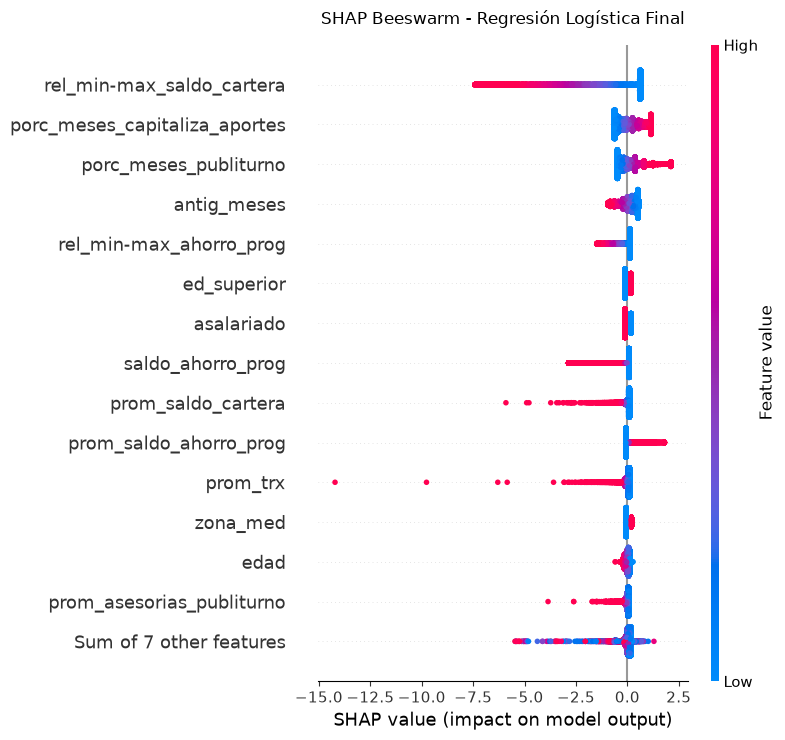

In [44]:
# ============================================================
# PASO 16
# SHAP - EXPLICABILIDAD DEL MODELO FINAL
# REGRESIÓN LOGÍSTICA
# ============================================================
#
# MODELO FINAL:
#     modelo_logistic_final
#
# ENTRENAMIENTO:
#     FIT + VALID
#
# TEST:
#     utilizado para calcular y visualizar explicaciones SHAP
#
# BACKGROUND:
#     muestra de observaciones de TEST
#
# IMPORTANTE:
# - No se reentrena el modelo.
# - No se vuelve a ajustar el scaler.
# - No se modifica class_weight ni el threshold.
# - SHAP se utiliza exclusivamente para explicar el modelo.
# ============================================================


# ============================================================
# 1. SEPARAR SCALER Y MODELO LOGÍSTICO
# ============================================================

scaler = modelo_logistic_final.named_steps["scaler"]

modelo_logistico = modelo_logistic_final.named_steps["model"]


# ============================================================
# 2. ESTANDARIZAR TEST
# ============================================================
#
# Se utiliza el scaler ya entrenado con FIT + VALID.
# No se ajusta nuevamente con TEST.
# ============================================================

X_test_scaled_array = scaler.transform(X_test)


# Convertir a DataFrame para conservar los nombres originales
# y el orden de las variables.

X_test_scaled = pd.DataFrame(
    X_test_scaled_array,
    columns=X_test.columns,
    index=X_test.index
)


# ============================================================
# 3. CREAR BACKGROUND PARA SHAP
# ============================================================
#
# Se utiliza una muestra representativa de TEST como background.
# Para conjuntos grandes, una muestra reduce el costo
# computacional sin necesidad de utilizar todas las filas.
#
# Si TEST tiene 1000 observaciones o menos, se utilizan todas.
# ============================================================

BACKGROUND_SIZE = min(
    1000,
    len(X_test_scaled)
)

X_background = X_test_scaled.sample(
    n=BACKGROUND_SIZE,
    random_state=42
)


masker = shap.maskers.Independent(
    X_background,
    max_samples=BACKGROUND_SIZE
)


# ============================================================
# 4. CREAR EXPLICADOR SHAP
# ============================================================

explainer = shap.LinearExplainer(
    modelo_logistico,
    masker
)


# ============================================================
# 5. CALCULAR VALORES SHAP
# ============================================================
#
# Se explican todas las observaciones de TEST.
# El background es una muestra de TEST.
# ============================================================

shap_values = explainer(
    X_test_scaled
)


# ============================================================
# 6. CONSERVAR LOS NOMBRES ORIGINALES DE LAS VARIABLES
# ============================================================

shap_values.feature_names = X_test.columns.tolist()


# ============================================================
# 7. GRÁFICA BEESWARM
# ============================================================
#
# Permite observar:
# - Importancia global de las variables.
# - Dirección de la contribución SHAP.
# - Distribución de las contribuciones entre observaciones.
# - Relación entre el valor de cada variable y su contribución.
# ============================================================

plt.figure()

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Beeswarm - Regresión Logística Final",
    pad=15
)

plt.tight_layout()

plt.show()

Si bien la Regresion Logística posee, en sí misma, coeficientes que permiten evaluar el impacto de cada predictor sobre la variable objetivo, hemos decidido utilizar la librería SHAP con fines exploratorios. De este modo, podemos apreciar que:

-No radicar solicitudes de retiro es propiciado por:

+ Valores altos de rel_min_max_cartera.
+ Valores bajos de porc_capitalizacion_meses_aportes.
+ Valores bajos de porc_meses_publiturno.
+ Valores altos de antigüedad en meses.
+ Educación superior = 0.
+ Valores altos de rel_min_max_ahorro_programado.
+ Asalariado = 1.
+ Valores altos de ahorro programado al corte.
+ Valores bajos de promedio_saldo_ahorro_programado.
+ zona medellín = 0
+ Valores altos de promedio saldo cartera al corte.
+ Valores altos de promedio transacciones por mes.
+ Valores altos de edad.
+ Valores altos de promedio mensual asesorías publiturno.

Radicar solicitudes de retiro es propiciado por:

+ Valores bajos de rel_min_max_cartera.
+ Valores altos de porc_capitalizacion_meses_aportes.
+ Valores altos de porc_meses_publiturno.
+ Valores bajos de antigüedad en meses.
+ Educación superior = 1.
+ Valores bajos de rel_min_max_ahorro_programado.
+ Asalariado = 0.
+ Valores bajos de ahorro programado al corte.
+ Valores altos de promedio_saldo_ahorro_programado.
+ zona medellín = 1.
+ Valores bajos de promedio saldo cartera al corte.
+ Valores bajos de promedio transacciones por mes.
+ Valores bajos de edad.
+ Valores bajos de promedio mensual asesorías publiturno.


## 13.3 Síntesis

Este trabajo tenía el propósito de predecir la probabilidad de que un asociado de Confiar decida radicar una solicitud de retiro total e identificar los factores que propician su retención.

Mediante el desarrollo de este ejercicio fue posible constatar que un modelo de regresión logística ajustado permite efectuar una clasificación orientada por reglas de negocio que optimizan los verdaderos negativos. __Si bien este modelo puede servir como una línea base para iniciar la implementación de medidas para mitigar la solicitud de retiro, la relación entre los valores f1 score, precision y recall para la clase minoritaria, así como el incremento de la desviación estandar entre folds del recall para dicha clase durante el testeo, muestran que su precisión sería susceptible de mejora, sobre todo si se tiene en cuenta que, durante el consurso de modelos, hubo algunos, como Gradient Boosting y Random Forest, que mostraron mejor rendimiento general y específico. Otra limitación que cabe reconocer es que el modelo fue diseñado con datos que recogen una visión histórica de cada asociado a partir de 2017. Así, entonces, el modelo no está diseñado para predecir el retiro de personas de las que no se tiene todo su historial (personas, por ejemplo, que ingresaron a la cooperativa antes de 2016).__  

En cuanto a la explicabilidad del modelo, sus resultados coinciden con el comportamiento observado en la cotidianidad de los clientes: los indicadores altos de cartera (promedio, rel_min_max), unidos a valores altos de saldo en cuenta y ahorro programado al corte, junto con transacciones promedio altas dan cuenta de actividad financiera que reduce el interés por interponer solicitudes de retiro. 
Por el contrario, indicadores bajos de cartera (rel_min_max), valores altos de ahorro programado promedio, poca antigüedad y una actividad intensa de visita a las agencias y abono a los aportes favorece que las personas pongan especial atención en los aportes sociales – por encima de los beneficios que recibe a través de estos – y los conciban como un ahorro del cual pueden disponer si efectúan solicitud de retiro.


## Bibliografía

Bonilla, N., Montero, E., González, J. (2021). Pronóstico del retiro de un asociado a partir de las principales condiciones comerciales y socioeconómicas. Los Libertadores Fundación Universitaria. Bogotá, Colombia. 

[https://repository.libertadores.edu.co/server/api/core/bitstreams/8d2654b1-9563-4ba6-8c5f-f4bbf37f4799/content](https://repository.libertadores.edu.co/server/api/core/bitstreams/8d2654b1-9563-4ba6-8c5f-f4bbf37f4799/content)

Customer Churn Prediction, disponible en [https://www.kaggle.com/code/nishakumarids/customer-churn-prediction](https://www.kaggle.com/code/nishakumarids/customer-churn-prediction)

Fajardo, D., Motta, A. (2019). Modelo de abandono de clientes en una empresa de créditos en línea. Universidad de los Andes. Bogotá, Colombia. 

[https://repositorio.uniandes.edu.co/entities/publication/0233f1e9-4a2b-41ec-b1d6-4b27ed508a90](https://repositorio.uniandes.edu.co/entities/publication/0233f1e9-4a2b-41ec-b1d6-4b27ed508a90) 

Tafur, M., Dairo, W. (2024). Clusterización y aplicación de modelos predictivos para la identificación de factores que conlleven a una desafiliación de una cooperativa financiera. Universidad Nacional Abierta y a Distancia (UNAD). 

[https://repository.unad.edu.co/jspui/bitstream/10596/67241/1/wdmorenot.pdf](https://repository.unad.edu.co/jspui/bitstream/10596/67241/1/wdmorenot.pdf) 

Raza, M., Manoj, J., Singh, A., Blumenstock, J. (2015). Behavioral Modeling for Churn Prediction: Early Indicators and Accurate Predictors of Custom Defection and Loyalty. 2015 Institute of Electrical and Electronics Engineers International Conference on Services Economics (SE).  

[https://arxiv.org/pdf/1512.06430](https://arxiv.org/pdf/1512.06430)
 
Zambrano, Karol. "Fidelización en el sector cooperativo de carácter institucional en Ecuador". Estudios de la Gestión: revista internacional de administración. 6 (II Semestre, 2019): 111-133. 

[https://repositorio.uasb.edu.ec/items/9b891aa1-1753-46eb-b48f-d56f72dbb173](https://repositorio.uasb.edu.ec/items/9b891aa1-1753-46eb-b48f-d56f72dbb173) 

